# PROG8431 — Solutions to Highway Congestion
## Workshop B: K-Means Clustering

**Group members:** Jasper Lim (9117038), John Buni (9115726), Eche Oji (9078881)  
**GitHub repository:** https://github.com/JohnBuni/Data-Analysis-Project-Group4.git

**Purpose.** Building on Workshop A, we use K-means to group Ontario highway segments with similar **2024 annual average daily traffic (AADT)** and **segment length**. This helps us recognize different traffic-demand patterns across the highway network, beyond comparisons of overall averages. AADT measures traffic volume, **not congestion or delays**.

**Approach:** inspect and clean data → select and standardize two variables → choose *k* using an elbow chart and cluster comparisons → summarize and interpret the groups.

## 1. Data setup and exploration

The notebook requires `pandas`, `matplotlib`, `scikit-learn`, and `openpyxl` (to read Excel files). If any are missing, install them once in a Jupyter code cell using `%pip install pandas matplotlib scikit-learn openpyxl`.

The Excel file is stored in the **`data` folder beside this notebook**. We first inspect missing values, descriptive statistics, and histograms to understand the distributions of AADT and segment distance before cleaning and clustering. The histograms use logarithmic horizontal scales because both variables have wide ranges and are strongly right-skewed.

In [1]:
# Load the tools and 2024 Ontario highway data
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

df = pd.read_excel("./data/Provincial Highways Traffic Volumes 2024 AADT Only.xlsx")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2712, 5)


,Highway,Location Description From,Location Description To,Distance (KM),2024 AADT
0,QEW,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,CENTRAL AV IC,0.230,13400.0
1,QEW,CENTRAL AV IC,CONCESSION RD IC-1,0.933,19100.0
2,QEW,CONCESSION RD IC-1,THOMPSON RD IC-2,1.045,18300.0
3,QEW,THOMPSON RD IC-2,GILMORE RD IC-5,2.450,22600.0
4,QEW,GILMORE RD IC-5,BOWEN RD IC-7,2.059,26300.0


In [2]:
# Examine data types, missing values, and numerical distributions
print("Data types and non-null counts:")
df.info()
print("\nMissing values:")
print(df.isna().sum())
print("\nDescriptive statistics:")
display(df[["Distance (KM)", "2024 AADT"]].describe().round(2))

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2712 entries, 0 to 2711
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Highway                    2408 non-null   object 
 1   Location Description From  2408 non-null   object 
 2   Location Description To    2408 non-null   object 
 3   Distance (KM)              2101 non-null   float64
 4   2024 AADT                  1810 non-null   float64
dtypes: float64(2), object(3)
memory usage: 106.1+ KB

Missing values:
Highway                      304
Location Description From    304
Location Description To      304
Distance (KM)                611
2024 AADT                    902
dtype: int64

Descriptive statistics:


,Distance (KM),2024 AADT
count,2101.00,1810.00
mean,9.12,31808.32
std,13.86,66712.33
min,0.10,10.00
25%,2.07,2012.50
50%,4.74,7350.00
75%,10.20,23500.00
max,178.60,511400.00


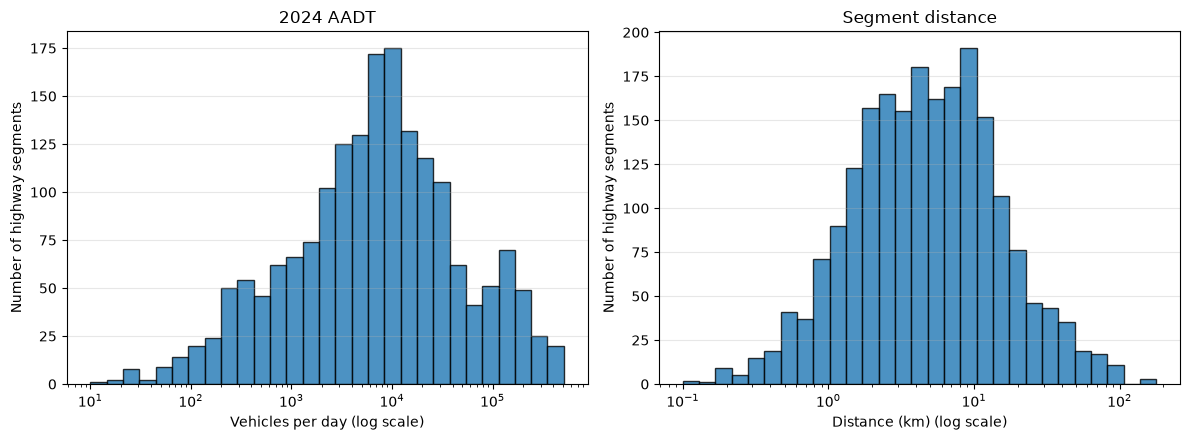

In [13]:
# Histograms show the distributions before cleaning
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

columns = [
    ("2024 AADT", "2024 AADT", "Vehicles per day"),
    ("Distance (KM)", "Segment distance", "Distance (km)")
]

for ax, (column, title, xlabel) in zip(axes, columns):
    values = df[column].dropna()
    values = values[values > 0]

    bins = np.logspace(np.log10(values.min()), np.log10(values.max()), 30)

    ax.hist(values, bins=bins, edgecolor="black", alpha=0.8)
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel(xlabel + " (log scale)")
    ax.set_ylabel("Number of highway segments")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### What we found, and how we cleaned the data

The source has **2,712 rows**. AADT is missing for **902** rows and distance is missing for **611**. Both variables are right-skewed: AADT has a mean of about **31,808** versus a median of **7,350**, and distance has a mean of **9.12 km** versus a median of **4.74 km**. The histograms show that most highway segments are concentrated at lower traffic volumes and shorter distances, while fewer segments have very large values. Both distributions have long upper tails. The logarithmic horizontal scales make these patterns easier to see without changing the values used for clustering.

We remove rows missing either clustering variable and exclude non-positive measurements. We **keep high values** because they could represent real differences among highways. We avoid filling missing AADT with an average, which could create artificial similarity. The missing records are a limitation: the clusters represent segments with usable measurements, not the entire highway network.

In [4]:
# Use complete, positive values; leave the original DataFrame unchanged
df_clean = df.dropna(subset=["Distance (KM)", "2024 AADT"]).copy()
df_clean = df_clean[
    (df_clean["Distance (KM)"] > 0) & (df_clean["2024 AADT"] > 0)
].copy()

print("Original segments:", len(df))
print("Segments retained:", len(df_clean))
print("Segments removed:", len(df) - len(df_clean))
print("Missing values remaining:")
print(df_clean[["Distance (KM)", "2024 AADT"]].isna().sum())

Original segments: 2712
Segments retained: 1810
Segments removed: 902
Missing values remaining:
Distance (KM)    0
2024 AADT        0
dtype: int64


## 2. Selecting and standardizing two variables

We use **2024 AADT** to represent traffic demand and **Distance (KM)** to represent segment length. The two variables may distinguish short, high-volume segments from longer, lower-volume segments. The highway number and location descriptions are kept for **interpreting** the clusters, not for calculating the distances between observations.

AADT and distance use very different numerical scales. Without scaling, AADT would dominate K-means' distance calculations. We use the class demonstration's **Z-score standardization** (subtract the mean and divide by the standard deviation), so both variables have mean 0 and standard deviation 1. Z-scores do not remove outliers.

In [5]:
# Same Z-score standardization function used in the class demonstration
def stamn(x):
    return (x - x.mean()) / x.std()

cluster_data = df_clean[["Distance (KM)", "2024 AADT"]].copy()
cluster_scaled = cluster_data.apply(stamn)
print("Means after standardization:")
print(cluster_scaled.mean().round(4))
print("Standard deviations after standardization:")
print(cluster_scaled.std().round(4))

Means after standardization:
Distance (KM)    0.0
2024 AADT        0.0
dtype: float64
Standard deviations after standardization:
Distance (KM)    1.0
2024 AADT        1.0
dtype: float64


## 3. Choosing the number of clusters (*k*)

We fit K-means for **k = 1 through 7**, following the professor's demonstration. The **within-cluster sum of squares (WCSS)** measures how tightly observations are grouped around their centres. WCSS decreases as k increases, so we look for a bend (*elbow*) where the improvement begins to slow. We then check scatterplots and cluster sizes before deciding.

We use scikit-learn's `KMeans`, the **same algorithm as the demonstration**, with `n_init=10` and a fixed `random_state=42` for reproducible results. The class example sets `max_iter=10`; we use the scikit-learn default limit of 300 to allow more iterations when needed. This is a parameter setting, **not a different algorithm**.

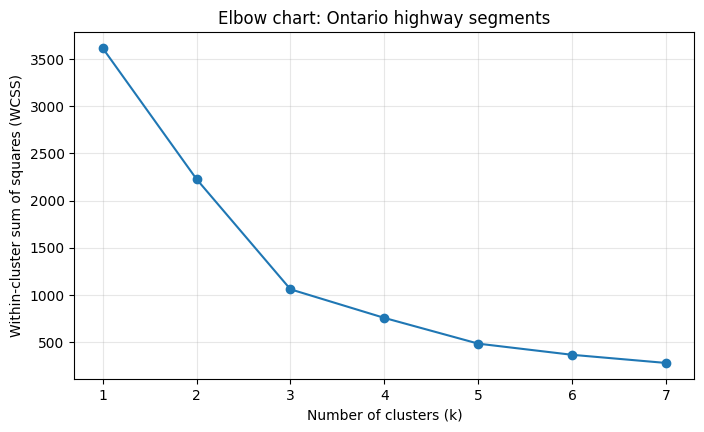

In [6]:
# Fit and retain models for k = 1 to 7, as in the class example
cluster_models = {}
wcss = []
for k in range(1, 8):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(cluster_scaled)
    cluster_models[k] = model
    wcss.append(model.inertia_)  # Within-cluster sum of squares

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, 8), wcss, marker="o")
plt.title("Elbow chart: Ontario highway segments")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squares (WCSS)")
plt.xticks(range(1, 8))
plt.grid(alpha=0.3)
plt.show()

### Elbow result and visual comparison

The WCSS drops sharply from **k = 1 to 3**, then decreases more slowly. This makes **k = 3** a reasonable candidate, but the elbow alone is not enough. Below, we compare **k = 3, 4, and 5**, including group sizes and the positions of their centres (red X markers).

Cluster sizes for k = 3: [1529, 165, 116]


Cluster sizes for k = 4: [1282, 160, 67, 301]
Cluster sizes for k = 5: [1255, 48, 66, 173, 268]


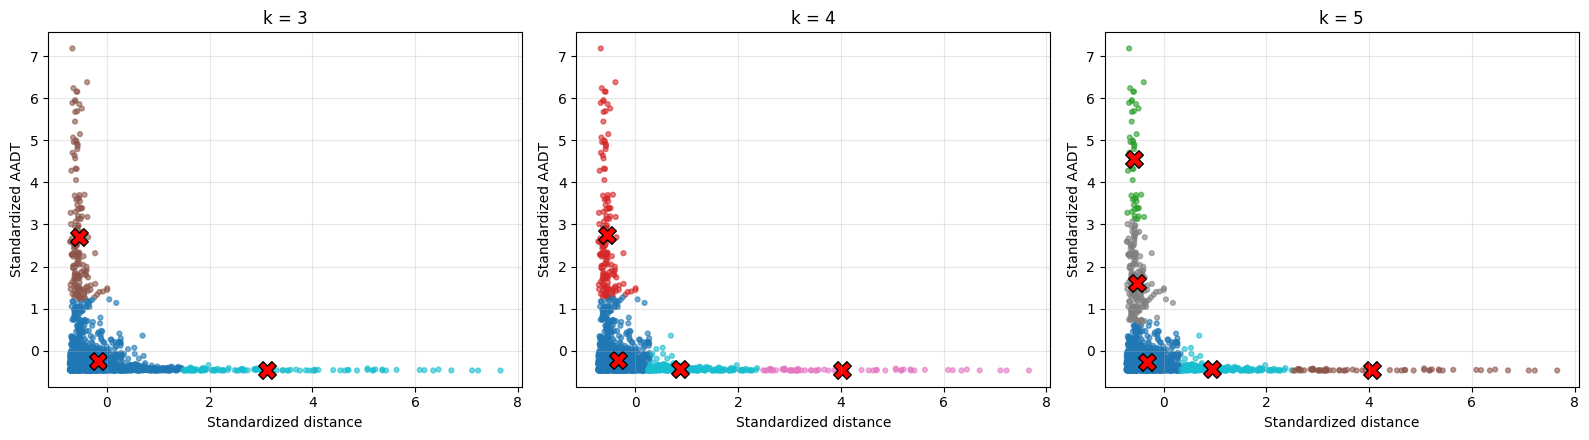

In [7]:
# Compare the same candidate solutions used in the class example
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, k in zip(axes, [3, 4, 5]):
    model = cluster_models[k]
    labels = model.labels_
    ax.scatter(cluster_scaled["Distance (KM)"], cluster_scaled["2024 AADT"],
               c=labels, cmap="tab10", s=12, alpha=0.6)
    ax.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
               c="red", marker="X", s=160, edgecolors="black")
    ax.set(title=f"k = {k}", xlabel="Standardized distance", ylabel="Standardized AADT")
    ax.grid(alpha=0.3)
    print(f"Cluster sizes for k = {k}:", pd.Series(labels).value_counts().sort_index().tolist())
plt.tight_layout()
plt.show()

### Final choice: **k = 3**

The elbow and scatterplots support **three broad, interpretable groups**: short-to-medium segments with relatively moderate traffic, short segments with very high traffic, and long segments with very low traffic. At **k = 3**, the group sizes are **1,529, 165, and 116**. With k = 4 and 5, these patterns split into smaller groups without providing a clear advantage for our purpose.

The large first cluster (**84.48%**) shows the groups are uneven. K-means does not require equal cluster sizes, but we acknowledge this limitation. We choose **k = 3 for interpretability**, not because it is the only possible answer. We also report the class demonstration’s **total, within-cluster, and between-cluster sums of squares** for this final model. These are descriptive clustering measures, not prediction accuracy.

In [8]:
# Use the already-fitted k = 3 model; no need to fit it a second time
final_model = cluster_models[3]
df_clean["Cluster"] = final_model.labels_
print("Final cluster sizes:")
print(df_clean["Cluster"].value_counts().sort_index())
print("Iterations to convergence:", final_model.n_iter_)

# As in class: Total SS = Within-cluster SS + Between-cluster SS
total_ss = ((cluster_scaled - cluster_scaled.mean()) ** 2).sum().sum()
within_ss = final_model.inertia_
between_ss = total_ss - within_ss
print(f"Total SS: {total_ss:.2f}; Within SS: {within_ss:.2f}; Between SS: {between_ss:.2f}")

Final cluster sizes:
Cluster
0    1529
1     165
2     116
Name: count, dtype: int64
Iterations to convergence: 6
Total SS: 3618.00; Within SS: 1061.19; Between SS: 2556.81


## 4. Cluster summaries and insights

We describe the groups using **original AADT (vehicles/day) and distance (km)**, not Z-scores. We also report medians, since both variables are skewed. Cluster numbers are arbitrary labels; their descriptive names come from the data.

In [9]:
# Summarize original measurements and assign meaningful names
cluster_names = {
    0: "Short-to-Medium, Moderate-Volume",
    1: "Short, High-Volume",
    2: "Long, Low-Volume"
}
cluster_summary = df_clean.groupby("Cluster").agg(
    Segments=("2024 AADT", "count"),
    Mean_AADT=("2024 AADT", "mean"),
    Median_AADT=("2024 AADT", "median"),
    Mean_Distance_KM=("Distance (KM)", "mean"),
    Median_Distance_KM=("Distance (KM)", "median")
)
cluster_summary["Percentage"] = cluster_summary["Segments"] / len(df_clean) * 100
cluster_summary.insert(0, "Name", cluster_summary.index.map(cluster_names))
display(cluster_summary.round(2))

,Name,Segments,Mean_AADT,Median_AADT,Mean_Distance_KM,Median_Distance_KM,Percentage
Cluster,,,,,,,
0,"Short-to-Medium, Moderate-Volume",1529,14625.32,7000.0,6.94,5.20,84.48
1,"Short, High-Volume",165,212658.18,184200.0,2.35,2.04,9.12
2,"Long, Low-Volume",116,1054.66,550.0,47.91,44.06,6.41


### What the clusters tell us

- **Cluster 0 — Short-to-Medium, Moderate-Volume (1,529 segments; 84.48%):** Mean AADT **14,625** and mean distance **6.94 km**. This is the broad main group.
- **Cluster 1 — Short, High-Volume (165 segments; 9.12%):** Mean AADT **212,658** and mean distance **2.35 km**. Its high traffic demand makes it the most relevant group for *further* congestion investigation.
- **Cluster 2 — Long, Low-Volume (116 segments; 6.41%):** Mean AADT **1,055** and mean distance **47.91 km**. These segments have a different distance-and-demand pattern.

K-means uncovers differences hidden by the overall average. **High AADT alone does not prove traffic jams**: speed, capacity, and delays would be needed to study congestion directly.

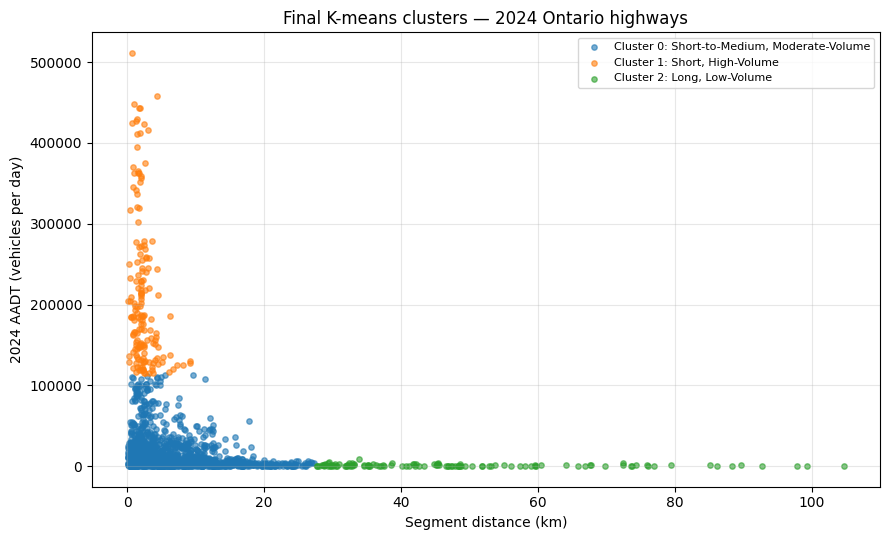

In [10]:
# Show the final groups in interpretable, original units
plt.figure(figsize=(9, 5.5))
for cluster_id, name in cluster_names.items():
    subset = df_clean[df_clean["Cluster"] == cluster_id]
    plt.scatter(subset["Distance (KM)"], subset["2024 AADT"],
                label=f"Cluster {cluster_id}: {name}", s=15, alpha=0.6)
plt.title("Final K-means clusters — 2024 Ontario highways")
plt.xlabel("Segment distance (km)")
plt.ylabel("2024 AADT (vehicles per day)")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Linking the results to actual highways

For each cluster, we count the **five most frequently represented highway numbers**. These are counts of recorded segments, **not** rankings of total highway length or congestion. We also display three high-AADT segments with their location descriptions to show how the original identifying columns can support follow-up work.

In [11]:
# Show the five most represented highways per cluster in one table
highway_counts = df_clean.groupby(["Cluster", "Highway"]).size().reset_index(name="Segments")
top_highways = (
    highway_counts.sort_values(["Cluster", "Segments"], ascending=[True, False])
    .groupby("Cluster").head(5)
)
display(top_highways[["Cluster", "Highway", "Segments"]])

# Examples using the original location-description columns
print("Three highest-AADT segments in Cluster 1:")
display(df_clean[df_clean["Cluster"] == 1]
        .nlargest(3, "2024 AADT")
        [["Highway", "Location Description From", "Location Description To",
          "Distance (KM)", "2024 AADT"]])

,Cluster,Highway,Segments
9,0,11,131
13,0,17,118
67,0,401,106
5,0,7,87
4,0,6,55
248,1,401,53
255,1,QEW,34
253,1,417,17
247,1,400,16
249,1,403,12


Three highest-AADT segments in Cluster 1:


,Highway,Location Description From,Location Description To,Distance (KM),2024 AADT
1584,401,HWY 427 IC 352,RENFORTH DR IC 349,0.763,511400.0
1585,401,RENFORTH DR IC 349,DIXIE RD IC 346,4.328,457800.0
1838,427,BURNHAMTHORPE RD IC-ETOBICOKE,RATHBURN RD IC-ETOBICOKE,1.011,448300.0


## 5. Conclusion and limitations

**Connection to Workshop A.** In the high-volume cluster, **Highway 401 has 53 recorded segments**, followed by the QEW (**34**), Highway 417 (**17**), and Highway 400 (**16**). Both Highways 401 and 400 therefore appear in this group, extending Workshop A's two-highway comparison to the wider network. Highways 11 and 17 are the most represented in the long, low-volume group (**16 and 14 segments**, respectively).

**Conclusion.** Using the class Z-score and K-means methods, we identified three useful types of Ontario highway segments. The high-volume group is a starting point for investigating congestion, **not proof that congestion exists**.

**Limitations:** We excluded **902 of 2,712 rows (33.3%)** with incomplete clustering data; missingness may bias the groups. Large values can influence K-means centres. Cluster 0 contains most observations, and the dataset covers **only 2024**, so it cannot show trends over time. Adding speeds, capacity, travel delays, or more years would improve a future congestion analysis.